## **Import Library**

In [1]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.9 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import datetime as dt
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## **Load Data and Cleaning**

In [4]:
# Membaca Dataset
df = pd.read_csv('/kaggle/input/datasets/maulanaandhika/wondr-bni-reviews/wondr_bni_reviews.csv')

df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,d10d5710-7283-45b2-8a41-fd6ceb4ce45f,arjuna jaya sakti jakarta,https://play-lh.googleusercontent.com/a/ACg8oc...,Great,5,0,1.5.0,2026-05-08 15:07:07,NaN,NaN,1.5.0
1,404611c1-94fd-4a9a-aa2d-816759962005,Afry Jehaman,https://play-lh.googleusercontent.com/a-/ALV-U...,baik,5,0,1.5.0,2026-05-08 15:02:10,NaN,NaN,1.5.0
2,3bacdb90-52d5-423a-81c0-c3f3e2259f8f,RAZKA Chanel,https://play-lh.googleusercontent.com/a-/ALV-U...,ok,5,0,1.5.0,2026-05-08 14:59:19,NaN,NaN,1.5.0
3,9913d2e3-21f9-43b6-b8f9-824cbb90bbcf,Royalcell,https://play-lh.googleusercontent.com/a/ACg8oc...,kak kok no rekening saya gak bisa dipake ya ka...,1,0,1.5.0,2026-05-08 14:52:59,"Halo Kak Royalcell, maaf atas kendalanya. Onea...",2026-05-09 01:47:04,1.5.0
4,2454f18b-324c-406f-947c-9db356ea3735,lorens mangapeng,https://play-lh.googleusercontent.com/a/ACg8oc...,"knpa wonder sllu ganguan trs?? tolong d,tngktk...",1,0,1.5.0,2026-05-08 14:40:22,"Halo Kak Lorens Mangapeng, maaf udah buat gak ...",2026-05-09 01:43:40,1.5.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              17000 non-null  object
 1   userName              17000 non-null  object
 2   userImage             17000 non-null  object
 3   content               17000 non-null  object
 4   score                 17000 non-null  int64 
 5   thumbsUpCount         17000 non-null  int64 
 6   reviewCreatedVersion  15274 non-null  object
 7   at                    17000 non-null  object
 8   replyContent          5270 non-null   object
 9   repliedAt             5270 non-null   object
 10  appVersion            15274 non-null  object
dtypes: int64(2), object(9)
memory usage: 1.4+ MB


In [6]:
# Hpaus kolom yang tidak digunakan
df = df.drop(columns=['reviewId', 'userName', 'userImage', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion'])

df.head()

,content,score
0,Great,5
1,baik,5
2,ok,5
3,kak kok no rekening saya gak bisa dipake ya ka...,1
4,"knpa wonder sllu ganguan trs?? tolong d,tngktk...",1


In [7]:
# Cek duplikat
df.duplicated().sum()

np.int64(6586)

In [8]:
print(df[df.duplicated()])

            content  score
6                ok      5
20               ok      5
22               ok      5
27            bagus      5
29            bagus      5
...             ...    ...
16985  terima kasih      5
16988        mantab      5
16989        Mantap      5
16992        mantab      5
16999         mntap      5

[6586 rows x 2 columns]


In [9]:
# Drop duplikat
df = df.drop_duplicates()

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10414 entries, 0 to 16998
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  10414 non-null  object
 1   score    10414 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 244.1+ KB


In [11]:
df.head()

,content,score
0,Great,5
1,baik,5
2,ok,5
3,kak kok no rekening saya gak bisa dipake ya ka...,1
4,"knpa wonder sllu ganguan trs?? tolong d,tngktk...",1


In [12]:
df.describe()

,score
count,10414.000000
mean,3.551373
std,1.744895
min,1.000000
25%,1.000000
50%,5.000000
75%,5.000000
max,5.000000


## **Text Preprocessing**

In [13]:
import re
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from io import StringIO
import requests

In [14]:
# Mengambil kamus bahasa gaul dari GitHub
url = 'https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv'
response = requests.get(url)

if response.status_code == 200:
    slang_df = pd.read_csv(StringIO(response.text))
    # Membuat dictionary dari kolom 'slang' (gaul) dan 'formal' (baku)
    slangwords = dict(zip(slang_df['slang'], slang_df['formal']))
    print(f"Berhasil memuat {len(slangwords)} kata slang")
else:
    print("Gagal mengambil data kamus slang")

Berhasil memuat 4331 kata slang


In [15]:
# Membuat objek stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def cleaningText(text):
    text = re.sub(r'@[A-Za-z0-9]+', '', text) # menghapus mention
    text = re.sub(r'#[A-Za-z0-9]+', '', text) # menghapus hashtag
    text = re.sub(r'RT[\s]', '', text) # menghapus RT
    text = re.sub(r"http\S+", '', text) # menghapus link
    text = re.sub(r'[0-9]+', '', text) # menghapus angka
    text = re.sub(r'[^\w\s]', '', text) # menghapus karakter selain huruf dan angka

    text = text.replace('\n', ' ') # mengganti baris baru dengan spasi
    text = text.translate(str.maketrans('', '', string.punctuation)) # menghapus semua tanda baca
    text = text.strip(' ') # menghapus karakter spasi dari kiri dan kanan teks
    return text

def casefoldingText(text): # Mengubah semua karakter dalam teks menjadi huruf kecil
    text = text.lower()
    return text

def fix_slangwords(text):
    words = text.split()
    fixed_words = []

    for word in words:
        if word.lower() in slangwords:
            fixed_words.append(slangwords[word.lower()])
        else:
            fixed_words.append(word)

    fixed_text = ' '.join(fixed_words)
    return fixed_text

def tokenizingText(text): # Memecah atau membagi string, teks menjadi daftar token
    text = word_tokenize(text)
    return text

def filteringText(text): # Menghapus stopwords dalam teks
    listStopwords = set(stopwords.words('indonesian'))
    listStopwords1 = set(stopwords.words('english'))
    listStopwords.update(listStopwords1)
    listStopwords.update(['iya','yaa','gak','nya','na','sih','ku',"di","ga","ya","gaa","loh","kah","woi","woii","woy"])
    filtered = []
    for txt in text:
        if txt not in listStopwords:
            filtered.append(txt)
    text = filtered
    return text

def stemmingText(text): # Mengurangi kata ke bentuk dasarnya yang menghilangkan imbuhan awalan dan akhiran atau ke akar kata
    # Menerapkan stemming pada setiap kata dalam daftar
    stemmed_words = [stemmer.stem(word) for word in text]

    # Menggabungkan kata-kata yang telah distem
    stemmed_text = ' '.join(stemmed_words)

    return stemmed_text


In [16]:
# Membersihkan teks dan menyimpannya di kolom 'text_clean'
df['text_clean'] = df['content'].apply(cleaningText)

# Mengubah huruf dalam teks menjadi huruf kecil dan menyimpannya di 'text_casefoldingText'
df['text_casefoldingText'] = df['text_clean'].apply(casefoldingText)

# Mengganti kata-kata slang dengan kata-kata standar dan menyimpannya di 'text_slangwords'
df['text_slangwords'] = df['text_casefoldingText'].apply(fix_slangwords)

# Memecah teks menjadi token (kata-kata) dan menyimpannya di 'text_tokenizingText'
df['text_tokenizingText'] = df['text_slangwords'].apply(tokenizingText)

# Menghapus kata-kata stop (kata-kata umum) dan menyimpannya di 'text_stopword'
df['text_stopword'] = df['text_tokenizingText'].apply(filteringText)

# Stemming
df['text_stemming'] = df['text_stopword'].apply(stemmingText)

df.head()

,content,score,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_stemming
0,Great,5,Great,great,great,[great],[great],great
1,baik,5,baik,baik,baik,[baik],[],
2,ok,5,ok,ok,ok,[ok],[ok],ok
3,kak kok no rekening saya gak bisa dipake ya ka...,1,kak kok no rekening saya gak bisa dipake ya ka...,kak kok no rekening saya gak bisa dipake ya ka...,kak kok no rekening saya enggak bisa dipakai y...,"[kak, kok, no, rekening, saya, enggak, bisa, d...","[kak, rekening, dipakai, kendala, banknyasama,...",kak rekening pakai kendala banknyasama saldo t...
4,"knpa wonder sllu ganguan trs?? tolong d,tngktk...",1,knpa wonder sllu ganguan trs tolong dtngktkan ...,knpa wonder sllu ganguan trs tolong dtngktkan ...,kenapa wonder selalu ganguan terus tolong dtng...,"[kenapa, wonder, selalu, ganguan, terus, tolon...","[wonder, ganguan, tolong, dtngktkan, aplikasinya]",wonder ganguan tolong dtngktkan aplikasi


## **Labelling**

In [17]:
import csv
import requests
from io import StringIO

# Membaca data kamus kata-kata positif dari GitHub
lexicon_positive = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_positive[row[0]] = int(row[1])
        # Menambahkan kata-kata positif dan skornya ke dalam kamus lexicon_positive
else:
    print("Failed to fetch positive lexicon data")

# Membaca data kamus kata-kata negatif dari GitHub
lexicon_negative = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_negative[row[0]] = int(row[1])
        # Menambahkan kata-kata negatif dan skornya dalam kamus lexicon_negative
else:
  print("Failed to fetch negative lexicon data")

In [18]:
# Fungsi untuk menentukan polaritas sentimen dari text
def sentiment_analysis_lexicon_indonesia(text):
    #for word in text:

    score = 0
    # Inisialisasi skor sentimen ke 0

    for word in text:
        # Mengulangi setiap kata dalam teks

        if (word in lexicon_positive):
            score = score + lexicon_positive[word]
            # Jika kata ada dalam kamus positif, tambahkan skornya ke skor sentimen

    for word in text:
        # Mengulangi setiap kata dalam teks (sekali lagi)

        if (word in lexicon_negative):
            score = score + lexicon_negative[word]
            # Jika kata ada dalam kamus negatif, kurangkan skornya dari skor sentimen

    polarity=''
    # Inisialisasi variabel polaritas

    if (score > 0):
        polarity = 'positive'
        # Jika skor sentimen lebih besar atau sama dengan 0, maka polaritas adalah positif
    elif (score < 0):
        polarity = 'negative'
        # Jika skor sentimen kurang dari 0, maka polaritas adalah negatif

    else:
        polarity = 'neutral'
    # Ini adalah bagian yang bisa digunakan untuk menentukan polaritas netral jika diperlukan

    return score, polarity
    # Mengembalikan skor sentimen dan polaritas teks

In [19]:
results = df['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
df['polarity_score'] = results[0]
df['polarity'] = results[1]

df.head()

,content,score,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_stemming,polarity_score,polarity
0,Great,5,Great,great,great,[great],[great],great,3,positive
1,baik,5,baik,baik,baik,[baik],[],,0,neutral
2,ok,5,ok,ok,ok,[ok],[ok],ok,4,positive
3,kak kok no rekening saya gak bisa dipake ya ka...,1,kak kok no rekening saya gak bisa dipake ya ka...,kak kok no rekening saya gak bisa dipake ya ka...,kak kok no rekening saya enggak bisa dipakai y...,"[kak, kok, no, rekening, saya, enggak, bisa, d...","[kak, rekening, dipakai, kendala, banknyasama,...",kak rekening pakai kendala banknyasama saldo t...,-1,negative
4,"knpa wonder sllu ganguan trs?? tolong d,tngktk...",1,knpa wonder sllu ganguan trs tolong dtngktkan ...,knpa wonder sllu ganguan trs tolong dtngktkan ...,kenapa wonder selalu ganguan terus tolong dtng...,"[kenapa, wonder, selalu, ganguan, terus, tolon...","[wonder, ganguan, tolong, dtngktkan, aplikasinya]",wonder ganguan tolong dtngktkan aplikasi,1,positive


## **Data Exploration**

In [20]:
print(df['polarity'].value_counts())

polarity
positive    4431
negative    3828
neutral     2155
Name: count, dtype: int64


/tmp/ipykernel_24/1018263110.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='polarity', data=df, palette='viridis', order=['positive', 'neutral', 'negative'])


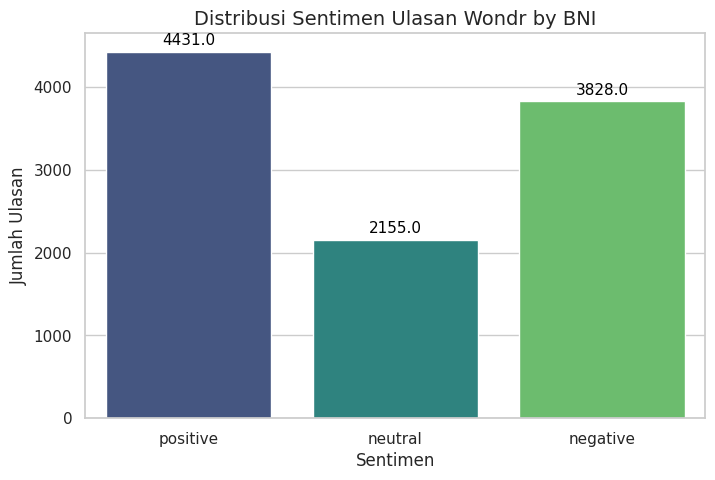

In [21]:
# Mengatur tema visualisasi
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
# Membuat bar chart
ax = sns.countplot(x='polarity', data=df, palette='viridis', order=['positive', 'neutral', 'negative'])

# Menambahkan label angka di atas setiap bar
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Distribusi Sentimen Ulasan Wondr by BNI', fontsize=14)
plt.xlabel('Sentimen', fontsize=12)
plt.ylabel('Jumlah Ulasan', fontsize=12)
plt.show()

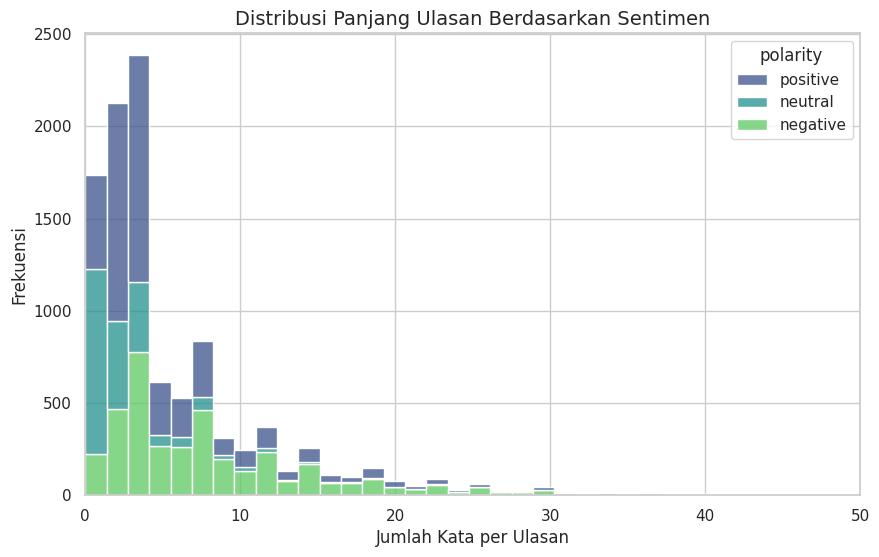

In [22]:
# Membuat kolom baru berisi jumlah kata pada masing-masing ulasan
df['word_count'] = df['text_stemming'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
# Membuat histogram
sns.histplot(data=df, x='word_count', hue='polarity', multiple='stack', bins=40, palette='viridis')

plt.title('Distribusi Panjang Ulasan Berdasarkan Sentimen', fontsize=14)
plt.xlabel('Jumlah Kata per Ulasan', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.xlim(0, 50) # Dibatasi sampai 50 kata agar grafik tidak terlalu panjang ke kanan (outliers)
plt.show()

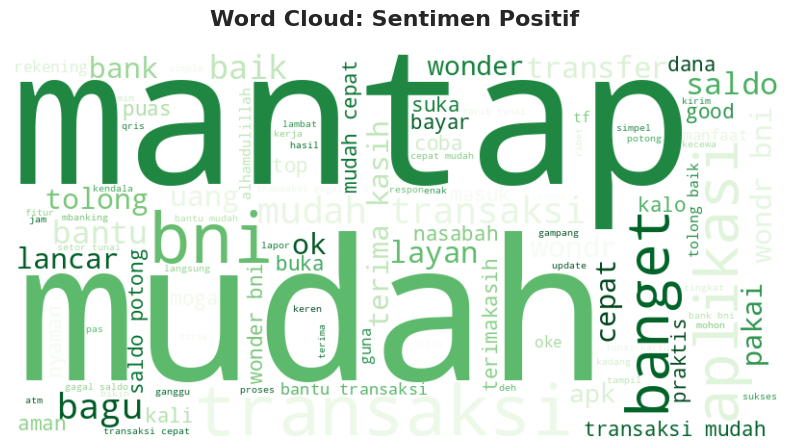

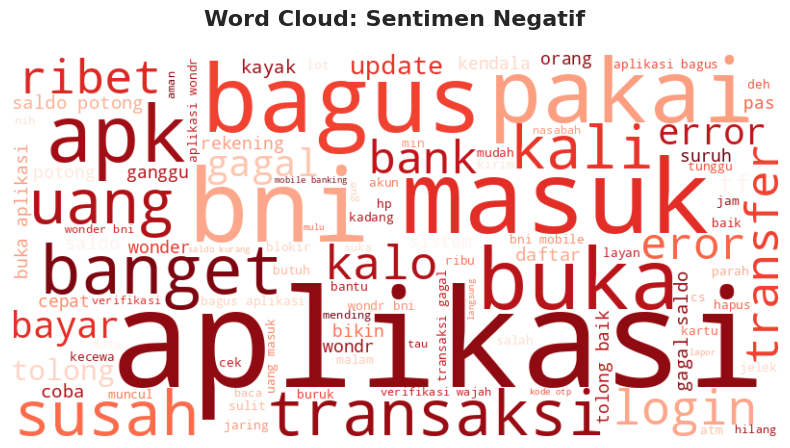

In [23]:
from wordcloud import WordCloud

# Menggabungkan semua teks berdasarkan kategori sentimen
text_positive = ' '.join(df[df['polarity'] == 'positive']['text_stemming'].astype(str))
text_negative = ' '.join(df[df['polarity'] == 'negative']['text_stemming'].astype(str))

# Fungsi pembantu untuk menggambar WordCloud
def plot_wordcloud(text, title, colormap):
    wordcloud = WordCloud(width=800, height=400,
                          background_color='white',
                          colormap=colormap,
                          max_words=100).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=16, fontweight='bold', pad=20)
    plt.axis('off')
    plt.show()

# Menampilkan WordCloud
plot_wordcloud(text_positive, 'Word Cloud: Sentimen Positif', 'Greens')
plot_wordcloud(text_negative, 'Word Cloud: Sentimen Negatif', 'Reds')

## **Modelling ML**

In [24]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

X = df['text_stemming'].astype(str)
y = df['polarity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Fungsi untuk evaluasi model
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    print(f"HASIL EVALUASI MODEL: {model_name}")

    # Cek apakah model adalah hasil GridSearchCV
    if hasattr(model, 'best_params_'):
        print("\nParameter Terbaik yang Ditemukan:")
        for param, value in model.best_params_.items():
            print(f" - {param}: {value}")

        print("\nBest cross-validation accuracy:", model.best_score_)

    else:
        print("\nModel Baseline ")

    # Memprediksi data Train dan Test
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Menghitung Akurasi
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print("\nAnalisis Akurasi")
    print(f"Akurasi Training : {acc_train:.4f}")
    print(f"Akurasi Test     : {acc_test:.4f}")

    # Classification Report
    print("\nClassification Report")
    print(classification_report(y_test, y_pred_test))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_test, labels=model.classes_)

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=model.classes_,
                yticklabels=model.classes_)
    plt.title(f'Confusion Matrix: {model_name}', fontsize=14, pad=15)
    plt.xlabel('Prediksi Model', fontsize=12)
    plt.ylabel('Label Sebenarnya (Ground Truth)', fontsize=12)
    plt.show()

### **Logistic Regression**

HASIL EVALUASI MODEL: Logistic Regression Baseline

Model Baseline 

Analisis Akurasi
Akurasi Training : 0.9226
Akurasi Test     : 0.8718

Classification Report
              precision    recall  f1-score   support

    negative       0.85      0.89      0.87       766
     neutral       0.83      0.79      0.81       431
    positive       0.91      0.90      0.90       886

    accuracy                           0.87      2083
   macro avg       0.86      0.86      0.86      2083
weighted avg       0.87      0.87      0.87      2083



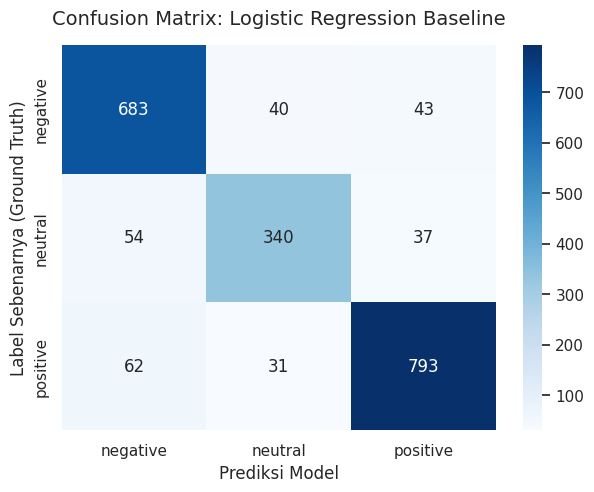

In [26]:
# Pipeline Baseline Logistic Regression
pipeline_default = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Fit dan Evaluasi
pipeline_default.fit(X_train, y_train)
evaluate_model(pipeline_default, X_train, y_train, X_test, y_test, "Logistic Regression Baseline")


Fitting 3 folds for each of 144 candidates, totalling 432 fits
HASIL EVALUASI MODEL: Logistic Regression - Grid Search

Parameter Terbaik yang Ditemukan:
 - clf__C: 1.0
 - tfidf__max_df: 0.7
 - tfidf__max_features: 1000
 - tfidf__min_df: 5
 - tfidf__ngram_range: (1, 1)

Best cross-validation accuracy: 0.8560797023166486

Analisis Akurasi
Akurasi Training : 0.9023
Akurasi Test     : 0.8713

Classification Report
              precision    recall  f1-score   support

    negative       0.87      0.89      0.88       766
     neutral       0.80      0.81      0.81       431
    positive       0.91      0.88      0.89       886

    accuracy                           0.87      2083
   macro avg       0.86      0.86      0.86      2083
weighted avg       0.87      0.87      0.87      2083



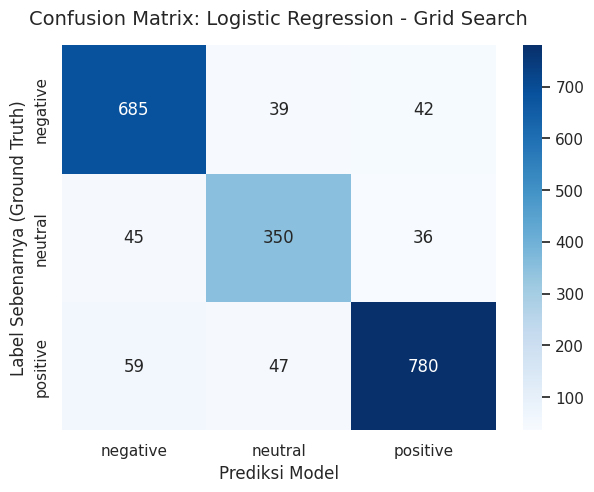

In [27]:
# Pipeline Grid Search Logistic Regression
pipeline_grid = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=1000))
])

param_grid = {
    'tfidf__max_features': [1000, 3000, 5000],
    'tfidf__min_df': [5, 10, 15, 17],
    'tfidf__max_df': [0.7, 0.8],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'clf__C': [0.1, 1.0, 10.0]
}

# Grid Search
grid_lr = GridSearchCV(pipeline_grid, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)

# Fit dan Evaluasi
grid_lr.fit(X_train, y_train)
evaluate_model(grid_lr, X_train, y_train, X_test, y_test, "Logistic Regression - Grid Search")

### **Random Forest**

HASIL EVALUASI MODEL: Random Forest - Baseline

Model Baseline 

Analisis Akurasi
Akurasi Training : 0.9921
Akurasi Test     : 0.8541

Classification Report
              precision    recall  f1-score   support

    negative       0.80      0.90      0.85       766
     neutral       0.85      0.81      0.83       431
    positive       0.91      0.84      0.87       886

    accuracy                           0.85      2083
   macro avg       0.86      0.85      0.85      2083
weighted avg       0.86      0.85      0.85      2083



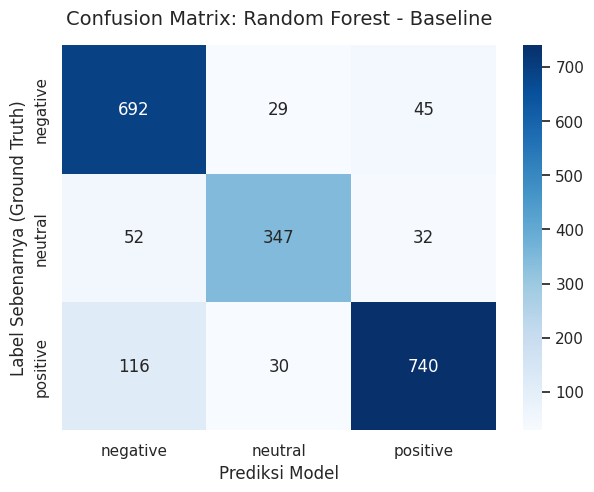

In [28]:
# Pipeline Baseline Random Forest
pipeline_rf_default = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', RandomForestClassifier(random_state=42))
])

# Fit dan Evaluasi
pipeline_rf_default.fit(X_train, y_train)
evaluate_model(pipeline_rf_default, X_train, y_train, X_test, y_test, "Random Forest - Baseline")

### **SVM**

HASIL EVALUASI MODEL: SVM - Baseline

Model Baseline 

Analisis Akurasi
Akurasi Training : 0.9687
Akurasi Test     : 0.8713

Classification Report
              precision    recall  f1-score   support

    negative       0.84      0.90      0.87       766
     neutral       0.87      0.77      0.81       431
    positive       0.90      0.90      0.90       886

    accuracy                           0.87      2083
   macro avg       0.87      0.85      0.86      2083
weighted avg       0.87      0.87      0.87      2083



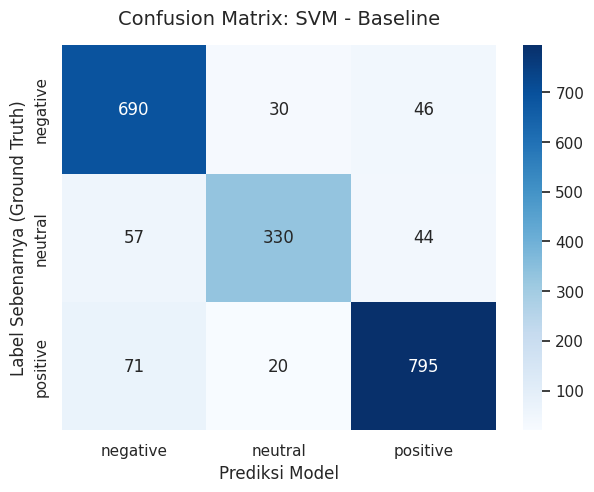

In [29]:
from sklearn.svm import SVC
# Pipeline Baseline SVM
pipeline_svm_default = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', SVC(random_state=42))
])

# Fit dan evaluasi
pipeline_svm_default.fit(X_train, y_train)
evaluate_model(pipeline_svm_default, X_train, y_train, X_test, y_test, "SVM - Baseline")

## **Modelling LSTM**

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Menghapus nilai NaN jika ada dan memastikan format string
X = df['text_stemming']
y = df['polarity'].values

# Encode Label (negative = 0, neutral = 1, positive = 2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# One-hot encoding untuk LSTM
y_categorical = to_categorical(y_encoded)

# Split data (80% Train, 20% Test)
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

In [31]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Parameter LSTM
max_features = 5000  # Maksimal kosa kata yang disimpan
maxlen = 100         # Maksimal panjang kalimat

# Tokenisasi
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(X_train_lstm)

X_train_seq = tokenizer.texts_to_sequences(X_train_lstm)
X_test_seq = tokenizer.texts_to_sequences(X_test_lstm)

# Padding
X_train_pad = pad_sequences(X_train_seq, maxlen=maxlen)
X_test_pad = pad_sequences(X_test_seq, maxlen=maxlen)

# Membangun Arsitektur LSTM
model_lstm = Sequential([
    Embedding(max_features, 128, input_length=maxlen),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax') # 3 kelas: Positif, Negatif, Netral
])

model_lstm.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_lstm.summary()

# Pelatihan Model LSTM
history_lstm = model_lstm.fit(
    X_train_pad, y_train_lstm,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_pad, y_test_lstm)
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1792483595.314464      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792483595.318409      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 49s 311ms/step - accuracy: 0.6518 - loss: 0.7867 - val_accuracy: 0.8200 - val_loss: 0.5153
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 310ms/step - accuracy: 0.8669 - loss: 0.4059 - val_accuracy: 0.8608 - val_loss: 0.3977
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 313ms/step - accuracy: 0.9085 - loss: 0.2876 - val_accuracy: 0.8613 - val_loss: 0.3966
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 313ms/step - accuracy: 0.9275 - loss: 0.2319 - val_accuracy: 0.8608 - val_loss: 0.4066
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 307ms/step - accuracy: 0.9371 - loss: 0.2012 - val_accuracy: 0.8646 - val_loss: 0.4317
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 312ms/step - accuracy: 0.9419 - loss: 0.1868 - val_accuracy: 0.8569 - val_loss: 0.4535
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 312ms/step - accuracy: 0.9462 - loss: 0.1733 - val_accuracy: 0.8555 - val_loss: 0.4799
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 314ms/step - accuracy: 0.9525 - loss: 0

## **Modelling IndoBERT**

In [32]:
!pip install -q transformers accelerate

In [33]:
import torch
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback, AutoConfig)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

MODEL_NAME = 'indobenchmark/indobert-base-p1'
MAX_LEN = 128
OUTPUT_DIR = 'indobert_wondr'

# label mapping
label_list = sorted(df["polarity"].unique())

label2id = {
    label: i
    for i, label in enumerate(label_list)
}

id2label = {
    i: label
    for label, i in label2id.items()
}

print("label_list:", label_list)
print("label2id:", label2id)
print("id2label:", id2label)

assert len(label_list) == 3
assert len(label2id) == 3
assert len(id2label) == 3

config = AutoConfig.from_pretrained(MODEL_NAME)

config.num_labels = len(label_list)
config.id2label = id2label
config.label2id = label2id


# Cek sebelum membuat model
print("\nCONFIG SEBELUM MODEL:")
print("num_labels :", config.num_labels)
print("id2label   :", config.id2label)
print("label2id   :", config.label2id)

Device: cuda
label_list: ['negative', 'neutral', 'positive']
label2id: {'negative': 0, 'neutral': 1, 'positive': 2}
id2label: {0: 'negative', 1: 'neutral', 2: 'positive'}


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]


CONFIG SEBELUM MODEL:
num_labels : 3
id2label   : {0: 'negative', 1: 'neutral', 2: 'positive'}
label2id   : {'negative': 0, 'neutral': 1, 'positive': 2}


In [34]:
# Teks untuk BERT: tanpa stopword removal & stemming
X_bert = df['text_slangwords'].astype(str)
y_bert = df['polarity'].map(label2id)

# Split Train-test
X_tr, X_test_b, y_tr, y_test_b = train_test_split (
    X_bert, y_bert, test_size=0.2, random_state=42, stratify=y_bert)

# Split Validation
X_train_b, X_val_b, y_train_b, y_val_b = train_test_split (
    X_tr, y_tr, test_size=0.1, random_state=42, stratify=y_tr)

print(f'Train: {len(X_train_b)}, Val: {len(X_val_b)}, Test: {len(X_test_b)}')

Train: 7497, Val: 834, Test: 2083


In [35]:
tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer_bert(list(texts), truncation=True,
                                        max_length=MAX_LEN, padding=False)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item['labels'] = int(self.labels[idx])
        return item

train_ds = ReviewDataset(X_train_b, y_train_b)
val_ds   = ReviewDataset(X_val_b,   y_val_b)
test_ds  = ReviewDataset(X_test_b,  y_test_b)

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [36]:
model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    config=config
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(labels, preds),
            'precision': precision, 'recall': recall, 'f1': f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=8,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=0.1,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to='none',
    seed=42
)

from transformers import DataCollatorWithPadding

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer_bert),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [37]:
# Pelatihan IndoBERT
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.229694,1.018065,0.812950,0.823986,0.799620,0.806062
2,0.731755,0.718909,0.878897,0.887115,0.860669,0.870447
3,0.450991,0.728863,0.877698,0.889104,0.859880,0.870276
4,0.309325,0.722825,0.881295,0.882416,0.867336,0.873116
5,0.195838,0.831386,0.894484,0.892143,0.880864,0.885935
6,0.110567,0.921589,0.889688,0.886616,0.875669,0.880621
7,0.083866,1.079480,0.887290,0.882605,0.878795,0.880176
8,0.043233,1.104323,0.888489,0.884040,0.876470,0.879842


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=944, training_loss=0.42110435942472035, metrics={'train_runtime': 478.4206, 'train_samples_per_second': 125.363, 'train_steps_per_second': 1.973, 'total_flos': 2111021131532418.0, 'train_loss': 0.42110435942472035, 'epoch': 8.0})

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


HASIL EVALUASI MODEL: IndoBERT
Akurasi Test : 0.8915

Classification Report
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90       766
     neutral       0.83      0.84      0.84       431
    positive       0.90      0.92      0.91       886

    accuracy                           0.89      2083
   macro avg       0.88      0.88      0.88      2083
weighted avg       0.89      0.89      0.89      2083



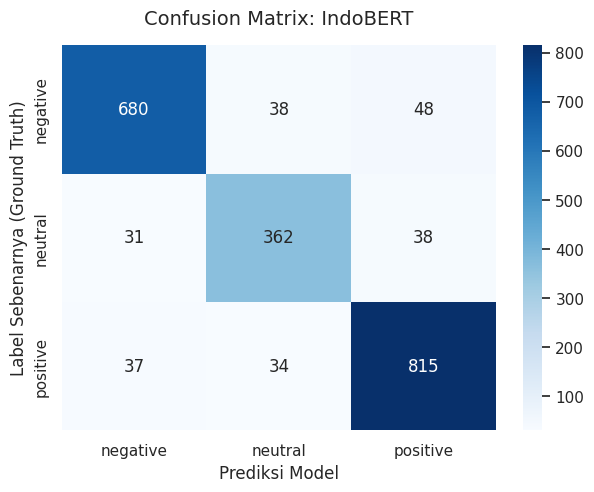

In [38]:
# Evaluasi pada data test
pred_output = trainer.predict(test_ds)
y_pred_bert = np.argmax(pred_output.predictions, axis=1)
y_true_bert = pred_output.label_ids

print('HASIL EVALUASI MODEL: IndoBERT')
print(f'Akurasi Test : {accuracy_score(y_true_bert, y_pred_bert):.4f}\n')
print('Classification Report')
print(classification_report(y_true_bert, y_pred_bert, target_names=label_list))

cm = confusion_matrix(y_true_bert, y_pred_bert)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_list, yticklabels=label_list)
plt.title('Confusion Matrix: IndoBERT', fontsize=14, pad=15)
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Label Sebenarnya (Ground Truth)', fontsize=12)
plt.show()

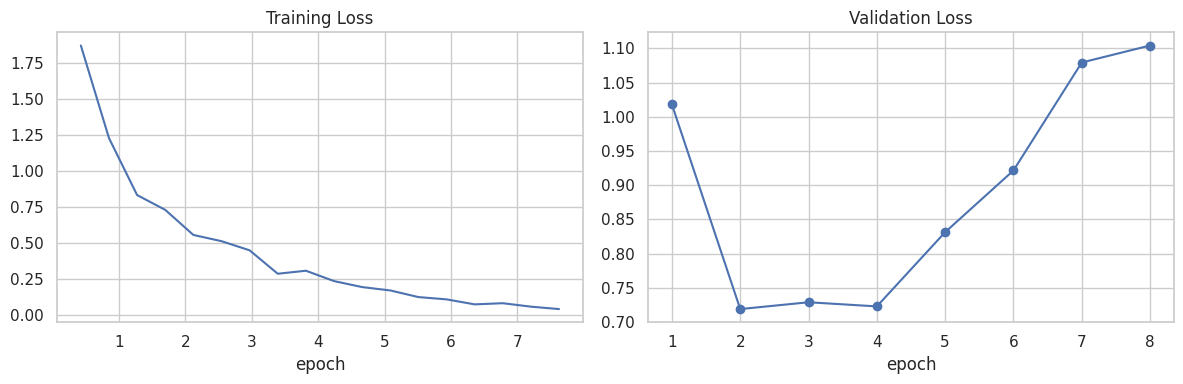

In [39]:
# Kurva loss selama pelatihan
log = pd.DataFrame(trainer.state.log_history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
log[log['loss'].notna()].plot(x='epoch', y='loss', ax=ax[0], title='Training Loss', legend=False)
log[log['eval_loss'].notna()].plot(x='epoch', y=['eval_loss'], ax=ax[1], title='Validation Loss', legend=False, marker='o')
plt.tight_layout()
plt.show()

In [40]:
# Simpan model & tokenizer untuk inference
trainer.save_model(OUTPUT_DIR)
tokenizer_bert.save_pretrained(OUTPUT_DIR)
print(f'Model tersimpan di folder: {OUTPUT_DIR}')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model tersimpan di folder: indobert_wondr


## **Inference Prediction**

In [41]:
# Fungsi Preprocessing untuk Data Baru
def preprocess_new_text(text):
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    text = tokenizingText(text)
    text = filteringText(text)
    text = stemmingText(text)
    return text

In [42]:
# Inference Logistic Regression
def predict_logistic_regression(text, model_pipeline):
    # Preprocess teks
    processed_text = preprocess_new_text(text)

    # Prediksi langsung menggunakan pipeline
    prediction = model_pipeline.predict([processed_text])
    return prediction[0]

# Contoh Penggunaan
kalimat_baru = "Aplikasi Wondr by BNI sangat memudahkan transaksi sehari-hari, mantap!"

# Inference
hasil_lr = predict_logistic_regression(kalimat_baru, grid_lr)

print(f"Teks Input : '{kalimat_baru}'")
print(f"Hasil Prediksi Logistic Regression : {hasil_lr.upper()}")

Teks Input : 'Aplikasi Wondr by BNI sangat memudahkan transaksi sehari-hari, mantap!'
Hasil Prediksi Logistic Regression : POSITIVE


In [43]:
# Inference LSTM
def predict_lstm(text, lstm_model, tokenizer_obj, label_encoder, max_length):
    # Preprocess teks
    processed_text = preprocess_new_text(text)

    # Tokenisasi dan Padding
    seq = tokenizer_obj.texts_to_sequences([processed_text])
    pad = pad_sequences(seq, maxlen=max_length)

    # Prediksi probabilitas dari model LSTM
    pred_probs = lstm_model.predict(pad, verbose=0)

    # Ambil indeks dengan probabilitas tertinggi
    pred_class_idx = np.argmax(pred_probs, axis=1)[0]

    # Decode indeks tersebut kembali menjadi teks label (negative/neutral/positive)
    pred_label = label_encoder.inverse_transform([pred_class_idx])[0]

    return pred_label, pred_probs[0]

# Contoh Penggunaan
kalimat_baru = "Aplikasi jelek tidak berguna"

hasil_lstm, probabilitas = predict_lstm(
    text=kalimat_baru,
    lstm_model=model_lstm,
    tokenizer_obj=tokenizer,
    label_encoder=le,
    max_length=maxlen
)

print(f"Teks Input : '{kalimat_baru}'")
print(f"Hasil Prediksi LSTM : {hasil_lstm.upper()}")
print(f"Probabilitas Kelas (Negatif, Netral, Positif) : {probabilitas}")

Teks Input : 'Aplikasi jelek tidak berguna'
Hasil Prediksi LSTM : NEGATIVE
Probabilitas Kelas (Negatif, Netral, Positif) : [9.9943966e-01 3.8561074e-04 1.7463497e-04]


In [44]:
# Inference Indobert
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Memuat model hasil pelatihan 
tokenizer_inf = AutoTokenizer.from_pretrained(OUTPUT_DIR)
model_inf = AutoModelForSequenceClassification.from_pretrained(OUTPUT_DIR).to(device)
model_inf.eval()

# Preprocessing khusus IndoBERT (tanpa stopword & stemming)
def preprocess_bert_text(text):
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    return text

def predict_indobert(texts, model=model_inf, tokenizer=tokenizer_inf, max_length=MAX_LEN):
    # Menerima satu string atau list string
    single = isinstance(texts, str)
    if single:
        texts = [texts]

    processed = [preprocess_bert_text(t) for t in texts]
    enc = tokenizer(processed, truncation=True, max_length=max_length,
                    padding=True, return_tensors='pt').to(model.device)

    with torch.no_grad():
        logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()

    results = []
    for p in probs:
        idx = int(np.argmax(p))
        results.append((model.config.id2label[idx], p))

    return results[0] if single else results

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [45]:
kalimat_baru = "Aplikasi Wondr by BNI sangat memudahkan transaksi sehari-hari, mantap!"

label, probs = predict_indobert(kalimat_baru)

print(f"Teks Input : '{kalimat_baru}'")
print(f"Hasil Prediksi IndoBERT : {label.upper()}")
print("Probabilitas Kelas :", {model_inf.config.id2label[i]: round(float(p), 4) for i, p in enumerate(probs)})

Teks Input : 'Aplikasi Wondr by BNI sangat memudahkan transaksi sehari-hari, mantap!'
Hasil Prediksi IndoBERT : POSITIVE
Probabilitas Kelas : {'negative': 0.0003, 'neutral': 0.0007, 'positive': 0.999}


In [46]:
# Contoh Penggunaan dan perbandingan dengan Logistic Regression dan LSTM
contoh = [
    "Aplikasi jelek tidak berguna, sering error pas login",
    "Mantap, transaksi jadi cepat dan mudah",
    "Biasa aja sih, belum ada fitur yang spesial",
    "Susah banget verifikasi wajah, udah berkali-kali gagal terus",
]

hasil_bert = predict_indobert(contoh)

rows = []
for teks, (lbl_bert, prob) in zip(contoh, hasil_bert):
    lbl_lr = predict_logistic_regression(teks, grid_lr)
    lbl_lstm, _ = predict_lstm(teks, model_lstm, tokenizer, le, maxlen)
    rows.append({'teks': teks, 'Logistic Regression': lbl_lr, 'LSTM': lbl_lstm,
                 'IndoBERT': lbl_bert, 'conf. IndoBERT': round(float(prob.max()), 4)})

pd.set_option('display.max_colwidth', 80)
pd.DataFrame(rows)

,teks,Logistic Regression,LSTM,IndoBERT,conf. IndoBERT
0,"Aplikasi jelek tidak berguna, sering error pas login",negative,negative,negative,0.9988
1,"Mantap, transaksi jadi cepat dan mudah",positive,positive,positive,0.9991
2,"Biasa aja sih, belum ada fitur yang spesial",neutral,neutral,positive,0.9945
3,"Susah banget verifikasi wajah, udah berkali-kali gagal terus",negative,negative,negative,0.9973


## **Export Model**

In [47]:
import os, json, pickle, shutil, joblib

EXPORT_DIR = 'exported_models'
os.makedirs(EXPORT_DIR, exist_ok=True)

def size_mb(path):
    if os.path.isdir(path):
        total = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs)
    else:
        total = os.path.getsize(path)
    return total / 1024 / 1024

In [48]:
# Model scikit-learn (pipeline TF-IDF dan classifier)
sklearn_models = {
    'logreg_baseline'  : pipeline_default,
    'logreg_gridsearch': grid_lr.best_estimator_,   # pipeline terbaik hasil GridSearchCV
    'random_forest'    : pipeline_rf_default,
    'svm'              : pipeline_svm_default,
}

for name, model in sklearn_models.items():
    path = os.path.join(EXPORT_DIR, f'{name}.joblib')
    joblib.dump(model, path, compress=3)
    print(f'{name:<18} disimpan di {path} ({size_mb(path):.2f} MB)')

logreg_baseline    disimpan di exported_models/logreg_baseline.joblib (0.14 MB)
logreg_gridsearch  disimpan di exported_models/logreg_gridsearch.joblib (0.03 MB)
random_forest      disimpan di exported_models/random_forest.joblib (9.69 MB)
svm                disimpan di exported_models/svm.joblib (0.40 MB)


In [49]:
# Model LSTM, tokenizer, dan label encoder
lstm_path = os.path.join(EXPORT_DIR, 'lstm_model.keras')
model_lstm.save(lstm_path)
print(f'LSTM model disimpan di {lstm_path} ({size_mb(lstm_path):.2f} MB)')

with open(os.path.join(EXPORT_DIR, 'lstm_tokenizer.pkl'), 'wb') as f:
    pickle.dump(tokenizer, f)          # tokenizer Keras (bukan tokenizer_bert)
with open(os.path.join(EXPORT_DIR, 'lstm_label_encoder.pkl'), 'wb') as f:
    pickle.dump(le, f)
print('LSTM tokenizer & label encoder berhasil disimpan')

LSTM model disimpan di exported_models/lstm_model.keras (7.95 MB)
LSTM tokenizer & label encoder berhasil disimpan


In [50]:
# 3) Model IndoBERT (format Hugging Face)
bert_dir = os.path.join(EXPORT_DIR, 'indobert')
trainer.save_model(bert_dir)            # bobot model terbaik (load_best_model_at_end=True)
tokenizer_bert.save_pretrained(bert_dir)
print(f'IndoBERT disimpan di {bert_dir}/ ({size_mb(bert_dir):.2f} MB)')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

IndoBERT disimpan di exported_models/indobert/ (475.42 MB)


In [51]:
# Kamus slang dan metadata
import sklearn, tensorflow as tf, transformers

with open(os.path.join(EXPORT_DIR, 'slangwords.json'), 'w', encoding='utf-8') as f:
    json.dump(slangwords, f, ensure_ascii=False)

metadata = {
    'labels_sklearn_and_bert': list(label_list),                 # ['negative', 'neutral', 'positive']
    'id2label_bert': {int(k): v for k, v in id2label.items()},
    'lstm': {'max_features': int(max_features), 'maxlen': int(maxlen),
             'classes': list(le.classes_)},
    'indobert': {'base_model': MODEL_NAME, 'max_len': int(MAX_LEN)},
    'preprocessing': {
        'sklearn_and_lstm': 'cleaning -> casefolding -> slang -> tokenizing -> stopword -> stemming (Sastrawi)',
        'indobert': 'cleaning -> casefolding -> slang (tanpa stopword & stemming)'
    },
    'versions': {'scikit-learn': sklearn.__version__, 'tensorflow': tf.__version__,
                 'transformers': transformers.__version__, 'torch': torch.__version__},
}
with open(os.path.join(EXPORT_DIR, 'metadata.json'), 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print('Slangwords.json & metadata.json disimpan')

Slangwords.json & metadata.json disimpan


In [52]:
# Kompres dan download
zip_path = shutil.make_archive('exported_models', 'zip', EXPORT_DIR)
print(f'Arsip: {zip_path} ({size_mb(zip_path):.2f} MB)')

print('\nIsi folder export:')
for root, _, files in os.walk(EXPORT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f' - {os.path.relpath(p, EXPORT_DIR):<45} {size_mb(p):8.2f} MB')

Arsip: /kaggle/working/exported_models.zip (458.62 MB)

Isi folder export:
 - logreg_baseline.joblib                            0.14 MB
 - logreg_gridsearch.joblib                          0.03 MB
 - lstm_label_encoder.pkl                            0.00 MB
 - lstm_model.keras                                  7.95 MB
 - lstm_tokenizer.pkl                                0.21 MB
 - metadata.json                                     0.00 MB
 - random_forest.joblib                              9.69 MB
 - slangwords.json                                   0.09 MB
 - svm.joblib                                        0.40 MB
 - indobert/config.json                              0.00 MB
 - indobert/model.safetensors                      474.74 MB
 - indobert/tokenizer.json                           0.68 MB
 - indobert/tokenizer_config.json                    0.00 MB
 - indobert/training_args.bin                        0.00 MB
